# Experiment 3: Breadth-First and Depth-First Search
**CSAI4014 AISR Laboratory** | Name: `<Suhani Baderia>` | SAP ID: `<500119327>` | Batch: `<4>`

A robot must find a path from **S** to **G** in a 4-connected grid maze. We run BFS (FIFO frontier,
`collections.deque`) and DFS (LIFO frontier) on **the same maze** and compare expansions, path
length, peak frontier size and run time, then validate both paths.

In [1]:
import os
import platform
import time
from collections import deque
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

os.makedirs("figs", exist_ok=True)
os.makedirs("tables", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150})
print("Python:", platform.python_version(), "| NumPy:", np.__version__, "| Matplotlib:", matplotlib.__version__)
print("OS    :", platform.platform())

Python: 3.13.9 | NumPy: 2.3.5 | Matplotlib: 3.10.6
OS    : Windows-11-10.0.26300-SP0


## Build the maze
A perfect maze is carved with a randomised depth-first "recursive backtracker" (fixed seed, so the
maze is reproducible). Then `EXTRA_OPENINGS` walls are knocked out to create loops: with loops
there are many S→G paths, so BFS and DFS can return different ones.
`0` = free cell, `1` = wall.

In [2]:
SEED = 9327              
H, W = 31, 41         
EXTRA_OPENINGS = 60

def make_maze(h, w, seed, extra):
    rng = np.random.default_rng(seed)
    g = np.ones((h, w), dtype=np.int8)
    stack = [(1, 1)]
    g[1, 1] = 0
    while stack:
        r, c = stack[-1]
        nbrs = [(r + dr, c + dc, r + dr // 2, c + dc // 2)
                for dr, dc in ((-2, 0), (2, 0), (0, -2), (0, 2))
                if 0 < r + dr < h - 1 and 0 < c + dc < w - 1 and g[r + dr, c + dc] == 1]
        if nbrs:
            nr, nc, wr, wc = nbrs[rng.integers(len(nbrs))]
            g[wr, wc] = g[nr, nc] = 0
            stack.append((nr, nc))
        else:
            stack.pop()
    walls = [(r, c) for r in range(1, h - 1) for c in range(1, w - 1)
             if g[r, c] == 1 and ((g[r - 1, c] == 0 and g[r + 1, c] == 0) or (g[r, c - 1] == 0 and g[r, c + 1] == 0))]
    for i in rng.choice(len(walls), size=min(extra, len(walls)), replace=False):
        g[walls[i]] = 0
    return g

maze = make_maze(H, W, SEED, EXTRA_OPENINGS)
START, GOAL = (1, 1), (H - 2, W - 2)
print(f"Maze {H} x {W}, free cells: {(maze == 0).sum()}, walls: {(maze == 1).sum()}")
MOVES = [(-1, 0), (0, 1), (1, 0), (0, -1)]      # N, E, S, W – same order for both searches

def neighbours(cell):
    r, c = cell
    for dr, dc in MOVES:
        nr, nc = r + dr, c + dc
        if 0 <= nr < H and 0 <= nc < W and maze[nr, nc] == 0:
            yield (nr, nc)

Maze 31 x 41, free cells: 659, walls: 612


## BFS and DFS
Both use graph search (a `parent` dictionary doubles as the visited set). A node is **expanded**
when it is taken off the frontier and its neighbours are generated. Frontier size is logged after
every expansion.

In [3]:
def reconstruct(parent, goal):
    path, node = [], goal
    while node is not None:
        path.append(node)
        node = parent[node]
    return path[::-1]

def bfs(start, goal):
    frontier, parent = deque([start]), {start: None}
    expansions, frontier_log = 0, []
    while frontier:
        node = frontier.popleft()                 # FIFO
        expansions += 1
        if node == goal:
            return reconstruct(parent, goal), expansions, frontier_log, parent
        for nb in neighbours(node):
            if nb not in parent:
                parent[nb] = node
                frontier.append(nb)
        frontier_log.append(len(frontier))
    return None, expansions, frontier_log, parent

def dfs(start, goal):
    frontier, parent, closed = [start], {start: None}, set()
    expansions, frontier_log = 0, []
    while frontier:
        node = frontier.pop()                     # LIFO
        if node in closed:
            continue
        closed.add(node)
        expansions += 1
        if node == goal:
            return reconstruct(parent, goal), expansions, frontier_log, closed
        for nb in reversed(list(neighbours(node))):   # reversed so N is tried first
            if nb not in closed:
                parent[nb] = node                 # last writer wins = DFS tree
                frontier.append(nb)
        frontier_log.append(len(frontier))
    return None, expansions, frontier_log, closed

def timed(fn, reps=20):
    best = float("inf")
    for _ in range(reps):
        t0 = time.perf_counter(); out = fn(START, GOAL); best = min(best, time.perf_counter() - t0)
    return out, best

(bfs_path, bfs_exp, bfs_front, bfs_seen), bfs_t = timed(bfs)
(dfs_path, dfs_exp, dfs_front, dfs_seen), dfs_t = timed(dfs)

## Path validation
A path is valid if it starts at S, ends at G, every cell is free, and consecutive cells are
4-neighbours (no jumps, no diagonal moves).

In [4]:
def validate(path):
    checks = {
        "starts at S": path[0] == START,
        "ends at G": path[-1] == GOAL,
        "all cells free": all(maze[r, c] == 0 for r, c in path),
        "unit 4-connected steps": all(abs(a[0] - b[0]) + abs(a[1] - b[1]) == 1 for a, b in zip(path, path[1:])),
        "no repeated cell": len(set(path)) == len(path),
    }
    return all(checks.values()), checks

for name, p in (("BFS", bfs_path), ("DFS", dfs_path)):
    ok, ch = validate(p)
    print(f"{name} path valid: {ok}  ->  {ch}")

BFS path valid: True  ->  {'starts at S': True, 'ends at G': True, 'all cells free': True, 'unit 4-connected steps': True, 'no repeated cell': True}
DFS path valid: True  ->  {'starts at S': True, 'ends at G': True, 'all cells free': True, 'unit 4-connected steps': True, 'no repeated cell': True}


## Observation table – BFS and DFS on the same maze

In [5]:
rows = [
    ["BFS", bfs_exp, len(bfs_path) - 1, max(bfs_front), bfs_t * 1e3, validate(bfs_path)[0]],
    ["DFS", dfs_exp, len(dfs_path) - 1, max(dfs_front), dfs_t * 1e3, validate(dfs_path)[0]],
]
hdr = ["Algorithm", "Nodes expanded", "Path length (moves)", "Max frontier", "Time (ms)", "Path valid"]
print(f"{hdr[0]:<10}{hdr[1]:>15}{hdr[2]:>21}{hdr[3]:>14}{hdr[4]:>11}{hdr[5]:>12}")
for r in rows:
    print(f"{r[0]:<10}{r[1]:>15}{r[2]:>21}{r[3]:>14}{r[4]:>11.3f}{str(r[5]):>12}")
np.savetxt("tables/T3_1_bfs_vs_dfs.csv", np.array(rows, dtype=object), fmt="%s", delimiter=",",
           header=",".join(hdr), comments="")
print(f"\nDFS path is {len(dfs_path) / len(bfs_path):.2f} x the BFS (shortest) path;"
      f" DFS expanded {dfs_exp / bfs_exp:.2f} x as many nodes as BFS.")

Algorithm  Nodes expanded  Path length (moves)  Max frontier  Time (ms)  Path valid
BFS                   658                   68            22      1.317        True
DFS                   107                   96            21      0.266        True

DFS path is 1.41 x the BFS (shortest) path; DFS expanded 0.16 x as many nodes as BFS.


## Figure 3.1 – maze with both paths

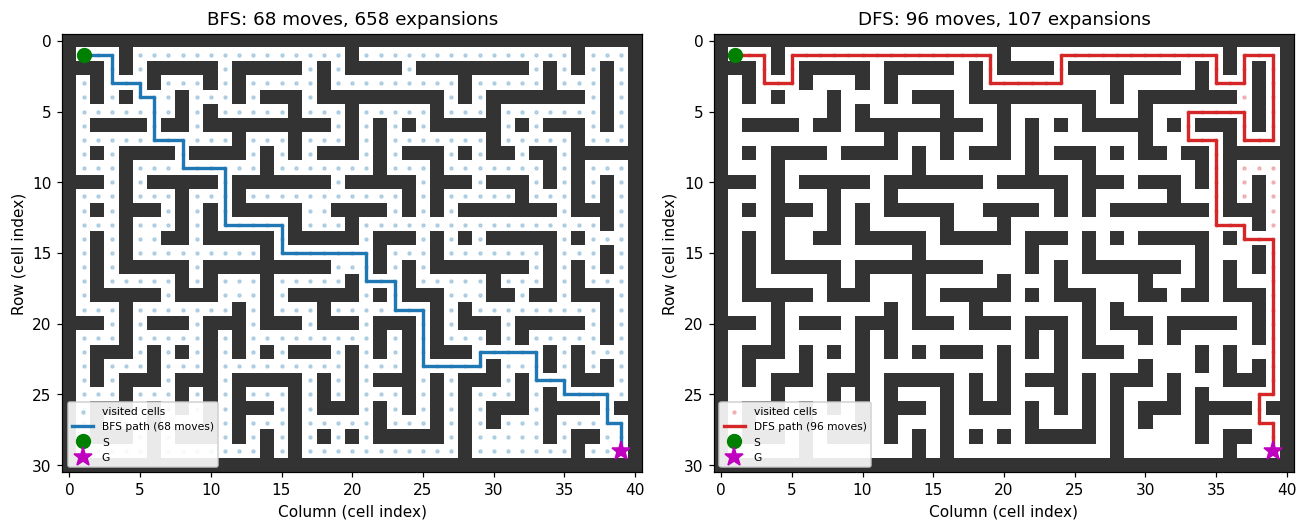

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.8))
cmap = ListedColormap(["white", "#333333"])
for ax, name, path, seen, col in ((axs[0], "BFS", bfs_path, bfs_seen, "tab:blue"),
                                  (axs[1], "DFS", dfs_path, dfs_seen, "tab:red")):
    ax.imshow(maze, cmap=cmap, interpolation="nearest")
    sr, sc = zip(*seen)
    ax.scatter(sc, sr, s=4, color=col, alpha=0.25, label="visited cells")
    pr, pc = zip(*path)
    ax.plot(pc, pr, color=col, lw=2.2, label=f"{name} path ({len(path) - 1} moves)")
    ax.plot(START[1], START[0], "go", ms=9, label="S")
    ax.plot(GOAL[1], GOAL[0], "m*", ms=13, label="G")
    ax.set_title(f"{name}: {len(path) - 1} moves, {bfs_exp if name == 'BFS' else dfs_exp} expansions")
    ax.set_xlabel("Column (cell index)"); ax.set_ylabel("Row (cell index)")
    ax.legend(loc="lower left", fontsize=7, framealpha=0.9)
fig.tight_layout()
fig.savefig("figs/fig3_1_maze_bfs_dfs_paths.png")
plt.show()

## Figure 3.2 – frontier size against expansion step

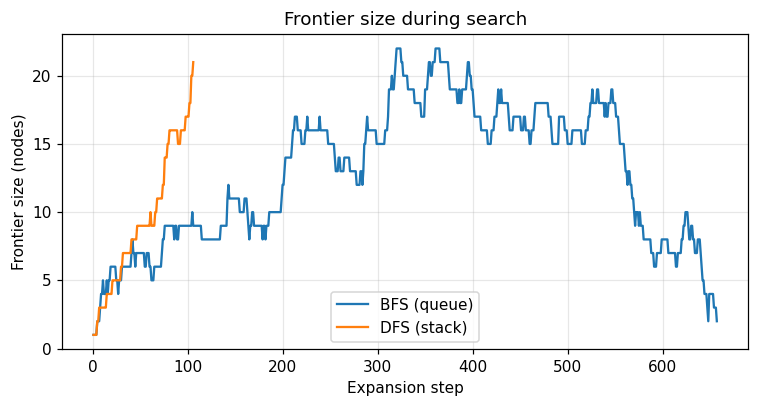

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(range(1, len(bfs_front) + 1), bfs_front, label="BFS (queue)")
ax.plot(range(1, len(dfs_front) + 1), dfs_front, label="DFS (stack)")
ax.set_xlabel("Expansion step")
ax.set_ylabel("Frontier size (nodes)")
ax.set_title("Frontier size during search")
ax.grid(alpha=0.3); ax.legend()
fig.tight_layout()
fig.savefig("figs/fig3_2_frontier_size.png")
plt.show()

## Extra: effect of maze seed (for the Discussion)
Repeating on 20 different mazes shows whether the pattern is general.

In [8]:
stats = []
for s in range(20):
    maze = make_maze(H, W, 100 + s, EXTRA_OPENINGS)
    b = bfs(START, GOAL); d = dfs(START, GOAL)
    stats.append([b[1], len(b[0]) - 1, max(b[2]), d[1], len(d[0]) - 1, max(d[2])])
stats = np.array(stats)
maze = make_maze(H, W, SEED, EXTRA_OPENINGS)        # restore the main maze
print("Mean over 20 mazes (BFS exp, BFS len, BFS maxF, DFS exp, DFS len, DFS maxF):")
print(np.round(stats.mean(0), 1))
print("DFS path longer than BFS in", int((stats[:, 4] > stats[:, 1]).sum()), "of 20 mazes;"
      " DFS expanded fewer nodes in", int((stats[:, 3] < stats[:, 0]).sum()), "of 20.")

Mean over 20 mazes (BFS exp, BFS len, BFS maxF, DFS exp, DFS len, DFS maxF):
[641.4  77.3  20.2 187.4 129.1  32.2]
DFS path longer than BFS in 20 of 20 mazes; DFS expanded fewer nodes in 19 of 20.
